---
# **Cuaderno 4:**  Crossroad Mutation cancer and rare diseases
---
* Author: Melissa Ormeño; Alexis Salas
* Laboratory: Cancer Molecular Dynamics
* Date: May 2026

**Aims:**

In [2]:
#Dependences
import matplotlib.pyplot as plt
import pandas as pd
import requests
import numpy as np

## Dataframes

In [3]:
#DF cancer
df_cancer = pd.read_csv("../data/TCGA/mutaciones_TCGA.csv")
df_cancer = df_cancer.drop(columns=["Patient_ID", "Tumor_Sample_Barcode"])
df_cancer['HGVSp_Short'] = df_cancer['HGVSp_Short'].replace('p.?', np.nan)
df_cancer = df_cancer.dropna(subset="HGVSp_Short")
df_cancer

,Hugo_Symbol,Chromosome,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,HGVSp,Project_ID,cancer_type
0,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-COAD,Colon
1,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-UCEC,Uterus
2,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-STAD,Stomach
3,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-COAD,Colon
4,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-STAD,Stomach
...,...,...,...,...,...,...,...,...,...,...,...
2466,ACVR1C,chr2,Missense_Mutation,Single base substitution,G,A,chr2:g.157538649G>A,S270L,p.?,TCGA-SKCM,Skin
2467,BMPR1A,chr10,Missense_Mutation,Single base substitution,G,A,chr10:g.86912317G>A,G203E,p.?,TCGA-SKCM,Skin
2468,BMPR1A,chr10,Nonsense_Mutation,Single base substitution,C,T,chr10:g.86923702C>T,Q528*,p.?,TCGA-SKCM,Skin
2469,AMHR2,chr12,Missense_Mutation,Single base substitution,G,A,chr12:g.53425181G>A,M147I,p.?,TCGA-SKCM,Skin


In [4]:
df_rare_diseases = pd.read_csv("../data/Mut_RareDiseases/mut_rarediseases_clean.txt", sep="\t")
df_rare_diseases.head(2)

FileNotFoundError: [Errno 2] No such file or directory: '../data/Mut_RareDiseases/mut_rarediseases_clean.txt'

## Clasificar dominios

In [6]:
#Clasificar  dominios
uniprot_ids =  ['O00238', 'P27037', 'P36894', 'P35790', 'P36897', 'P37023',
    'P37173', 'Q04771', 'Q13705', 'Q13873', 'Q16671', 'Q8NER5']

def get_features(uniprot_ids):

    features_dict = {}
    types = ["Signal", "Transmembrane",  "Domain"]
    
    """ Es decision del usuario de dejar "Topological domain", ya que este incluye tambien al dominio quinasa.
    Se quitaron las cadenas de "Region" y "Chain", ya que no se consideran dominios como tal. """

    for uniprot_id in uniprot_ids: 
        response = requests.get(f'https://rest.uniprot.org/uniprotkb/{uniprot_id}.json')
    
        if response.status_code == 200:
            json_data = response.json()
            gen_name = json_data['genes'][0]['geneName']['value']  # Extrae el nombre del gen
            features = json_data.get("features")

        features_dict[gen_name] = []
        
        for f in features:
            f_type = f.get("type")
            if f_type in types:
                f_start = f.get("location").get("start").get("value")
                f_end = f.get("location").get("end").get("value")
                f_description = f.get("description")
                f_domain_name = f_type if not f_description else f"{f_type}_{f_description}"
    
                # Guardar 
                features_dict[gen_name].append({
                    #"uniprot_id": uniprot_id,
                    #"gen_name": gen_name,
                    "Dominio": f_domain_name,
                    "Start": int(f_start),
                    "End": int(f_end),
                   
                })

    return features_dict

data = get_features(uniprot_ids)

def clasificar_mutacion(row):
   
    gene = row['Hugo_Symbol']
    mutation = row['HGVSp_Short']

    if gene in data:

        position = int(''.join(filter(str.isdigit, mutation)))
        
        # Recorrer la lista de dominios de ese gen
        for dominio in data[gene]:
            start = dominio["Start"]
            end = dominio["End"]
            nombre = dominio["Dominio"]
            
            if start <= position <= end:
            
                return pd.Series([nombre, f"{start}-{end}"])  # Dominio y rango

    return pd.Series(["Otro", None]) 

df_cancer[['Dominio', "Rango"]] = df_cancer.apply(clasificar_mutacion, axis=1)
df_cancer

,Hugo_Symbol,Chromosome,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,HGVSp,Project_ID,cancer_type,Dominio,Rango
0,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-COAD,Colon,Otro,None
1,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-UCEC,Uterus,Otro,None
2,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-STAD,Stomach,Otro,None
3,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-COAD,Colon,Otro,None
4,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-STAD,Stomach,Otro,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2466,ACVR1C,chr2,Missense_Mutation,Single base substitution,G,A,chr2:g.157538649G>A,S270L,p.?,TCGA-SKCM,Skin,Domain_Protein kinase,195-485
2467,BMPR1A,chr10,Missense_Mutation,Single base substitution,G,A,chr10:g.86912317G>A,G203E,p.?,TCGA-SKCM,Skin,Otro,None
2468,BMPR1A,chr10,Nonsense_Mutation,Single base substitution,C,T,chr10:g.86923702C>T,Q528*,p.?,TCGA-SKCM,Skin,Otro,None
2469,AMHR2,chr12,Missense_Mutation,Single base substitution,G,A,chr12:g.53425181G>A,M147I,p.?,TCGA-SKCM,Skin,Otro,None


## Crossroad mutations

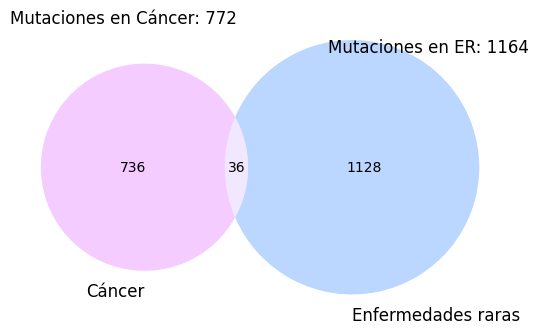

In [7]:
from matplotlib_venn import venn2

#PRAMETROS DF1 (cancer)
df1 = df_cancer
col_gen_df1 = "Hugo_Symbol"
col_mutation_df1 ="HGVSp_Short"

#PARAMETROS DF2 (enf raras)
df2 = df_rare_diseases
col_gen_df2 = "gene_name"
col_mutation_df2 = "Protein change"

# Combinar las columnas 'aa_mutation' y 'Gen_names' en df_cancer
mutaciones_df1 = set(df1.apply(lambda x: (x[col_mutation_df1], x[col_gen_df1]), axis=1).unique())

# Combinar las columnas 'aa_mutation' y 'GeneSymbol' en rare_disease_variations
mutaciones_df2 = set(df2.apply(lambda x: (x[col_mutation_df2], x[col_gen_df2]), axis=1).unique())

# Calcular el total de mutaciones
total_mutaciones_df1 = len(mutaciones_df1)
total_mutaciones_df2 = len(mutaciones_df2)
mutaciones_compartidas = len(mutaciones_df1.intersection(mutaciones_df2))

# Crear el diagrama de Venn
venn2([mutaciones_df1, mutaciones_df2], set_labels=('Cáncer', 'Enfermedades raras'), set_colors=('#e580ff33', '#5599ff3b'))

# Añadir el total de mutaciones al gráfico
total_mutaciones = total_mutaciones_df1 + total_mutaciones_df2 - mutaciones_compartidas
plt.text(-0.9, 0.5, f'Mutaciones en Cáncer: {total_mutaciones_df1}', fontsize=12, ha='left')
plt.text(0.9, 0.4, f'Mutaciones en ER: {total_mutaciones_df2}', fontsize=12, ha='right')

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../pictures/ven_merge_cancer_RD.png", format='png', dpi=600)

# Mostrar el diagrama
plt.show()

In [1]:
total_mutaciones_df1

NameError: name 'total_mutaciones_df1' is not defined

In [8]:
# Realizar el merge entre df_cancer y el DataFrame específico del gen
df_merge_genes = df_cancer.merge(df_rare_diseases, 
                                left_on=['Hugo_Symbol','HGVSp_Short'], right_on=['gene_name','Protein change'])
print(df_merge_genes['Hugo_Symbol'].unique())   
print(df_merge_genes.shape)
df_merge_genes

['BMPR2' 'TGFBR2' 'ACVRL1' 'BMPR1A' 'TGFBR1' 'ACVR2B' 'ACVR1' 'AMHR2'
 'BMPR1B']
(182, 27)


,Hugo_Symbol,Chromosome,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,HGVSp,Project_ID,...,Variant type,Molecular consequence,Germline classification,GRCh38Chromosome,GRCh38Location,VariationID,AlleleID(s),dbSNP ID,Canonical SPDI,Orphanet_Match
0,BMPR2,chr2,Nonsense_Mutation,Single base substitution,C,T,chr2:g.202377490C>T,Q6*,p.?,TCGA-BRCA,...,single nucleotide variant,nonsense,Pathogenic,20.0,202377490,264650,259244,rs886039219,NC_000002.12:202377489:C:T,Heritable pulmonary arterial hypertension
1,BMPR2,chr2,Nonsense_Mutation,Single base substitution,C,T,chr2:g.202377490C>T,Q6*,p.?,TCGA-BRCA,...,single nucleotide variant,nonsense,Pathogenic,20.0,202377490,264650,259244,rs886039219,NC_000002.12:202377489:C:T,Heritable pulmonary arterial hypertension
2,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,p.?,TCGA-COAD,...,single nucleotide variant,missense variant,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Sin coincidencias
3,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,p.?,TCGA-COAD,...,single nucleotide variant,missense variant,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Loeys-Dietz syndrome
4,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,p.?,TCGA-COAD,...,single nucleotide variant,missense variant,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Familial thoracic aortic aneurysm and aortic d...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
177,ACVRL1,chr12,Missense_Mutation,Single base substitution,G,A,chr12:g.51913237G>A,R67Q,p.?,TCGA-UCEC,...,single nucleotide variant,missense variant,Pathogenic/Likely pathogenic,120.0,51913237,212803,210224,rs863223414,NC_000012.12:51913236:G:A,Hereditary hemorrhagic telangiectasia
178,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691504C>T,R537C,p.?,TCGA-PAAD,...,single nucleotide variant,missense variant,Pathogenic/Likely pathogenic,30.0,30691504,12507,27546,rs104893809,NC_000003.12:30691503:C:T,Familial thoracic aortic aneurysm and aortic d...
179,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691504C>T,R537C,p.?,TCGA-PAAD,...,single nucleotide variant,missense variant,Pathogenic/Likely pathogenic,30.0,30691504,12507,27546,rs104893809,NC_000003.12:30691503:C:T,Loeys-Dietz syndrome
180,TGFBR2,chr3,Missense_Mutation,Single base substitution,A,G,chr3:g.30674123A>G,M425V,p.?,TCGA-ESCA,...,single nucleotide variant,missense variant,Pathogenic/Likely pathogenic,30.0,30674123,12517,27556,rs104893817,NC_000003.12:30674122:A:G,Familial thoracic aortic aneurysm and aortic d...


## Crossroad missense mutation

In [ ]:
df_cancer

In [ ]:
from matplotlib_venn import venn2

#PRAMETROS DF1 (cancer)
df1 = df_cancer
col_gen_df1 = "Hugo_Symbol"
col_mutation_df1 ="HGVSp_Short"

#PARAMETROS DF2 (enf raras)
df2 = df_rare_diseases
col_gen_df2 = "gene_name"
col_mutation_df2 = "Protein change"

# Combinar las columnas 'aa_mutation' y 'Gen_names' en df_cancer
mutaciones_df1 = set(df1.apply(lambda x: (x[col_mutation_df1], x[col_gen_df1]), axis=1).unique())

# Combinar las columnas 'aa_mutation' y 'GeneSymbol' en rare_disease_variations
mutaciones_df2 = set(df2.apply(lambda x: (x[col_mutation_df2], x[col_gen_df2]), axis=1).unique())

# Calcular el total de mutaciones
total_mutaciones_df1 = len(mutaciones_df1)
total_mutaciones_df2 = len(mutaciones_df2)
mutaciones_compartidas = len(mutaciones_df1.intersection(mutaciones_df2))

# Crear el diagrama de Venn
venn2([mutaciones_df1, mutaciones_df2], set_labels=('Cáncer', 'Enfermedades raras'), set_colors=('#e580ff33', '#5599ff3b'))

# Añadir el total de mutaciones al gráfico
total_mutaciones = total_mutaciones_df1 + total_mutaciones_df2 - mutaciones_compartidas
plt.text(-0.9, 0.5, f'Mutaciones en Cáncer: {total_mutaciones_df1}', fontsize=12, ha='left')
plt.text(0.9, 0.4, f'Mutaciones en ER: {total_mutaciones_df2}', fontsize=12, ha='right')

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../pictures/ven_merge_cancer_RD.png", format='png', dpi=600)

# Mostrar el diagrama
plt.show()

## Graficos 

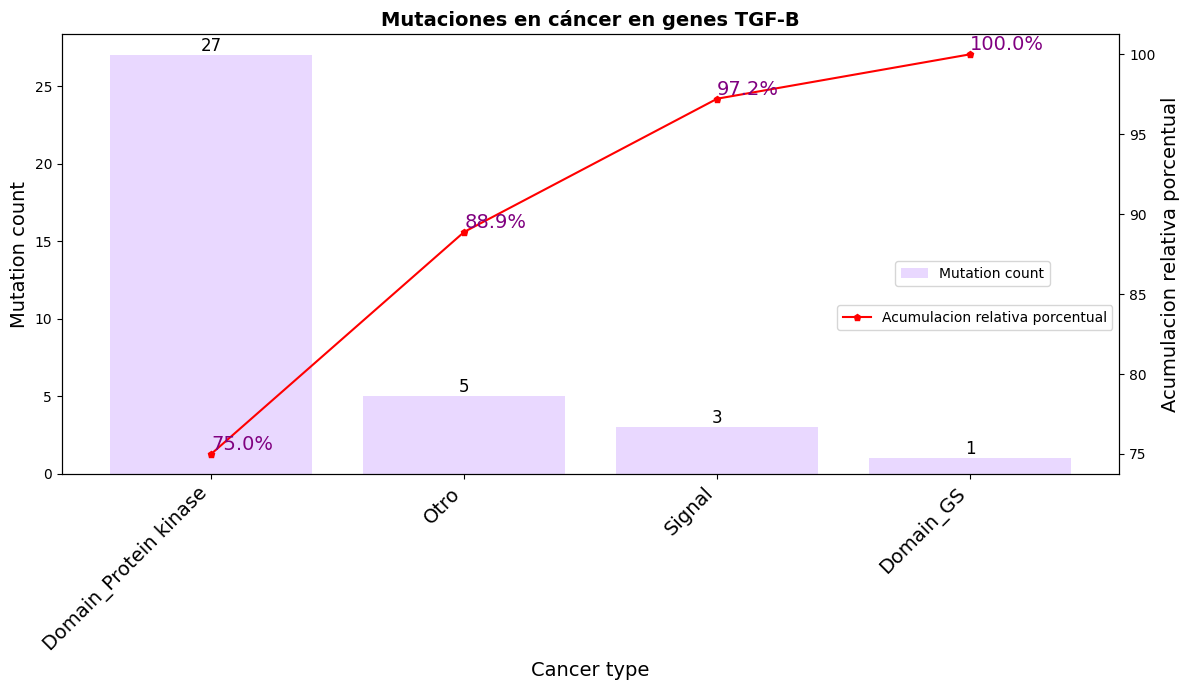

In [9]:
#PARAMETROS GENRALES
df = df_merge_genes #DATAFRAME A UTILIZAR
count = "HGVSp_Short" #COLUMNA QUE SE VA A CONTAR O SUMAR (eje Y)
grupo = "Dominio" #barras
mutation_counts = df.groupby(grupo, as_index=False)[count].nunique() #OPERACION 

#PARAMETROS DE ETIQUETA
ylabel = 'Mutation count' # Etiqueta eje y
ylabel2 = 'Acumulacion relativa porcentual' # Etiqueta eje 2
set_title = 'Mutaciones en cáncer en genes TGF-B' # Titulo del grafico
set_xlabel = 'Cancer type' # Titulo eje X
leyenda_2 = 'Acumulacion relativa porcentual' # Nombre leyenda eje 2
leyenda_count = 'Mutation count' # Nombre leyenda eje 1

#PARAMETROS COLORES
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

#PARAMETRO DE GUARDADO
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # Cambiar a "svg" si se quiere otro formato (png y svg deben estar en minuscula)
DPI = 600  # Se usará solo si FORMATO_IMAGEN == "png"
NOMBRE_IMAGEN = "mut_missense_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"


# Ordenar las mutaciones de mayor a menor
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calcular la acumulación relativa porcentual
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

# Gráfico de barras para el número de mutaciones
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])

# Gráfico de barras para la cantidad de mutaciones por tipo de cáncer
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# Crear un segundo eje y para la línea de acumulación relativa porcentual
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Agregar etiquetas con el número de mutaciones encima de las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Agregar etiquetas con el porcentaje acumulado en los puntos de la línea
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14)
# Ajustar límites y etiquetas
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# Ajustar las etiquetas del eje x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# Añadir leyendas
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  # Leyenda del primer eje
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  # Leyenda del segundo eje, un poco más abajo

# Ajustar el diseño para evitar solapamientos
plt.tight_layout()

# Guardar el gráfico en formato SVG antes de mostrarlo
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()